##CNN,Xgboost, MLP, RANDOM FOREST

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="absl")

In [1]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
df = pd.read_csv("Phishing_Detection_Dataset.csv", header=0)


Saving Phishing_Detection_Dataset.csv to Phishing_Detection_Dataset.csv


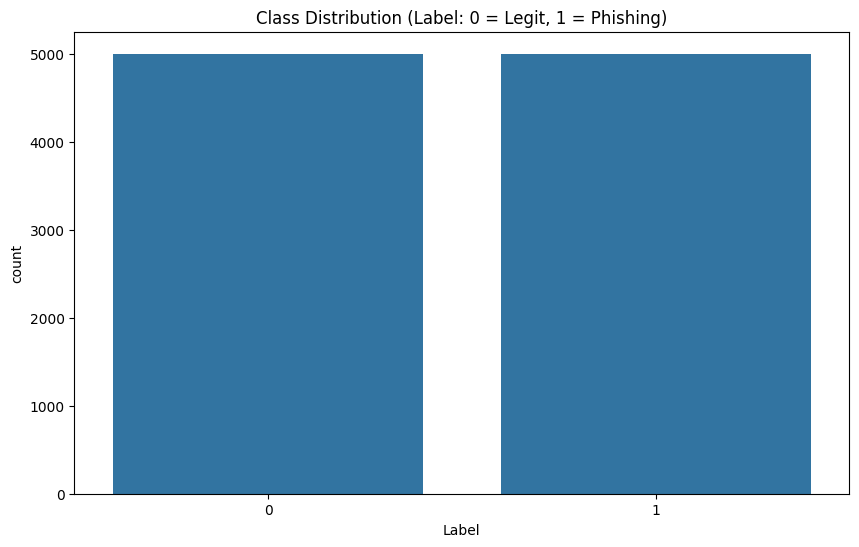

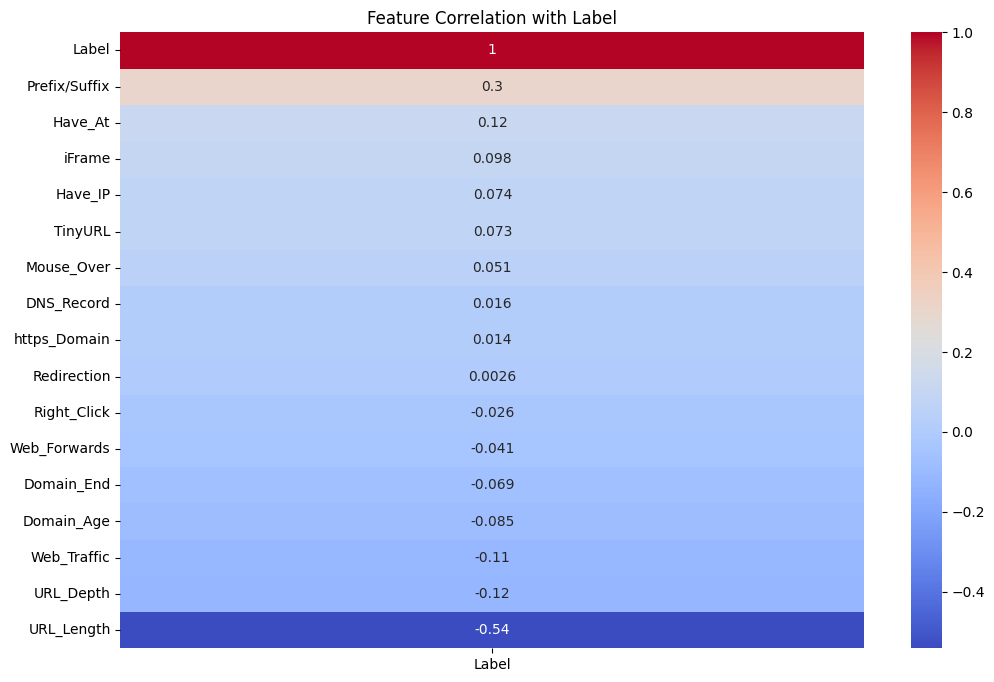

Selected 16 features out of 16


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:34:12] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:34:12] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:34:13] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Selected 14 features out of 16


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:34:13] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.82      0.94      0.88      1007
           1       0.93      0.79      0.85       993

    accuracy                           0.87      2000
   macro avg       0.88      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000


--- XGBoost Classification Report ---
              precision    recall  f1-score   support

           0       0.82      0.94      0.87      1007
           1       0.93      0.79      0.85       993

    accuracy                           0.86      2000
   macro avg       0.87      0.86      0.86      2000
weighted avg       0.87      0.86      0.86      2000

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

--- MLP Classification Report ---
              precision    recall  f1-score   support

           0       0.76      0.98      0.86      1007
           1       0.97      0.69     

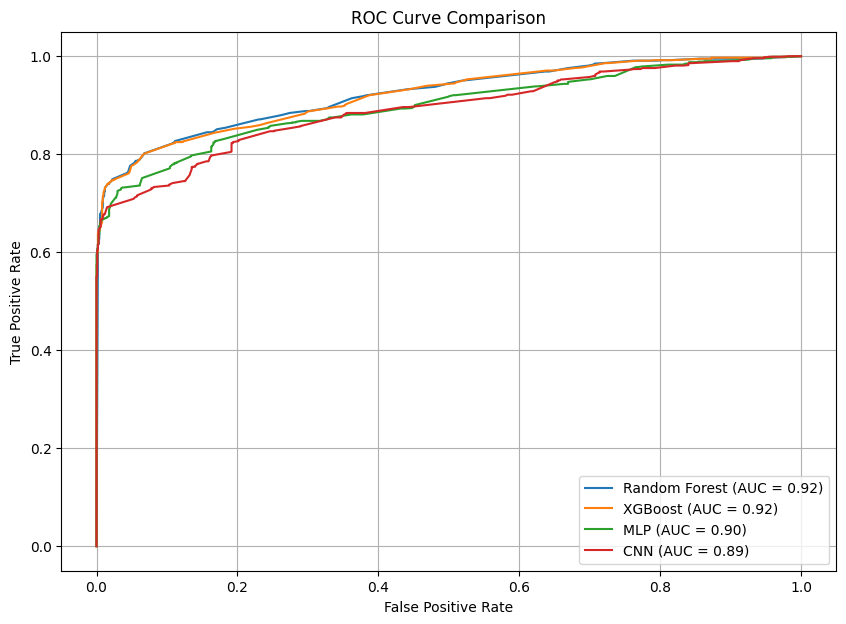

In [ ]:
import concurrent.futures
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.feature_selection import RFECV

# Deep Learning (Keras)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.optimizers import Adam

# Scikit-learn and XGBoost
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# ------------------------
# Load and Prepare Data
# ------------------------

# Replace this with your actual loading method
# Example: df = pd.read_csv("your_dataset.csv")
# For demo purposes, let's assume `df` is already loaded.

# Example visualization (Optional)
plt.figure(figsize=(10, 6))
sns.countplot(x='Label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(
    df.drop(columns=['Domain']).corr()[['Label']].sort_values('Label', ascending=False),
    annot=True,
    cmap='coolwarm'
)
plt.title('Feature Correlation with Label')
plt.show()

# Split Data
X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# For CNN, reshape the data to (samples, features, 1)
X_train_3d = np.expand_dims(X_train, axis=2)
X_test_3d = np.expand_dims(X_test, axis=2)

# ---------- Feature Selection Function ----------
def select_features_with_rfecv(estimator, X, y):
    rfecv = RFECV(estimator=estimator, step=1, cv=5, scoring='accuracy', n_jobs=-1)
    rfecv.fit(X, y)
    print(f"Selected {rfecv.n_features_} features out of {X.shape[1]}")
    return rfecv.transform(X), rfecv.support_

# ---------- Model Training Functions ----------
def train_rf():
    base_model = RandomForestClassifier(n_estimators=100, random_state=42)
    X_train_selected, support = select_features_with_rfecv(base_model, X_train, y_train)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train_selected, y_train)
    model._support_mask = support  # Save selected features
    return model

def train_xgb():
    base_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    X_train_selected, support = select_features_with_rfecv(base_model, X_train, y_train)
    model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    model.fit(X_train_selected, y_train)
    model._support_mask = support  # Save selected features
    return model

def train_mlp():
    model = Sequential([
        Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    model.fit(X_train, y_train, epochs=10, batch_size=32, verbose=0)
    return model

def train_cnn():
    model = Sequential([
        Conv1D(64, 3, activation='relu', input_shape=(X_train_3d.shape[1], 1)),
        MaxPooling1D(2),
        Flatten(),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    model.fit(X_train_3d, y_train, epochs=10, batch_size=32, verbose=0)
    return model

# ---------- Model Evaluation Function ----------
def evaluate_model(name, model, is_dl=False):
    if is_dl:
        X_eval = X_test_3d if name == 'CNN' else X_test
        preds = (model.predict(X_eval) > 0.5).astype("int32")
        probs = model.predict(X_eval)
    else:
        X_eval = X_test
        if hasattr(model, "_support_mask"):
            X_eval = X_eval[:, model._support_mask]
        preds = model.predict(X_eval)
        probs = model.predict_proba(X_eval)[:, 1]

    print(f"\n--- {name} Classification Report ---")
    print(classification_report(y_test, preds))

    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

# ---------- Run All Models ----------
rf_model = train_rf()
xgb_model = train_xgb()
mlp_model = train_mlp()
cnn_model = train_cnn()

# ---------- Evaluate and Plot ----------
plt.figure(figsize=(10, 7))

evaluate_model("Random Forest", rf_model)
evaluate_model("XGBoost", xgb_model)
evaluate_model("MLP", mlp_model, is_dl=True)
evaluate_model("CNN", cnn_model, is_dl=True)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


parallel training

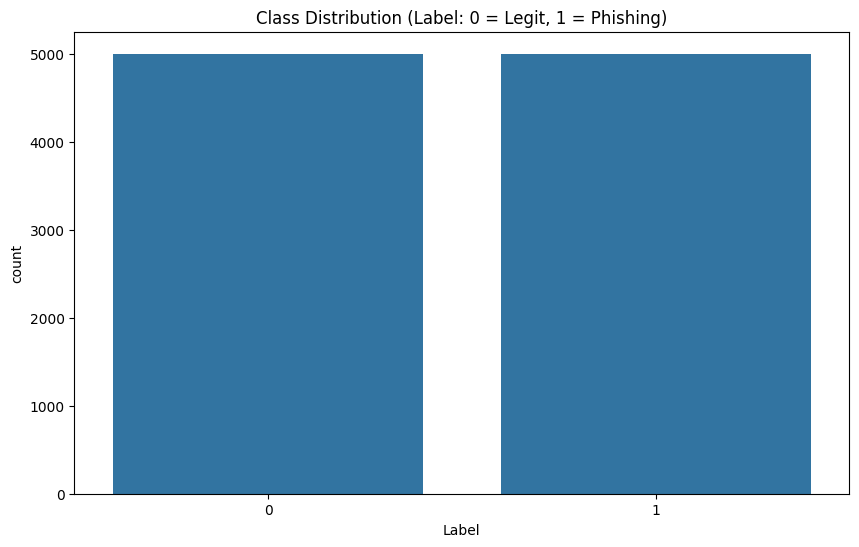

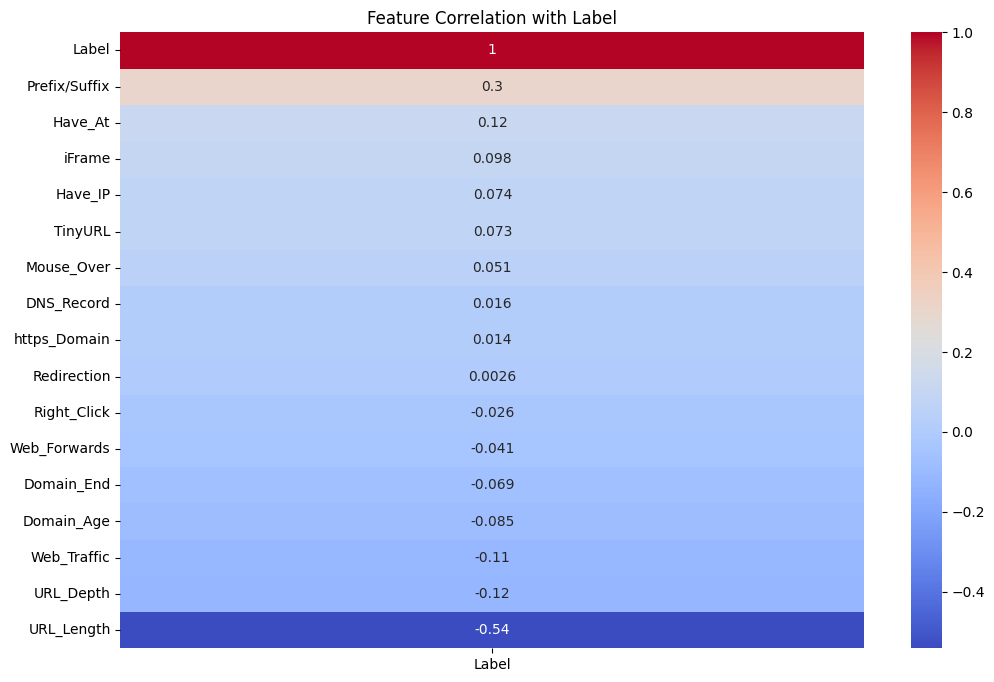

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.73      0.95      0.82      1000
           1       0.92      0.65      0.76      1000

    accuracy                           0.80      2000
   macro avg       0.83      0.80      0.79      2000
weighted avg       0.83      0.80      0.79      2000


=== XGBoost ===
              precision    recall  f1-score   support

           0       0.83      0.93      0.88      1000
           1       0.92      0.81      0.86      1000

    accuracy                           0.87      2000
   macro avg       0.88      0.87      0.87      2000
weighted avg       0.88      0.87      0.87      2000


=== Random Forest ===
              precision    recall  f1-score   support

           0       0.82      0.94      0.88      1000
           1       0.92      0.80      0.86      1000

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weigh

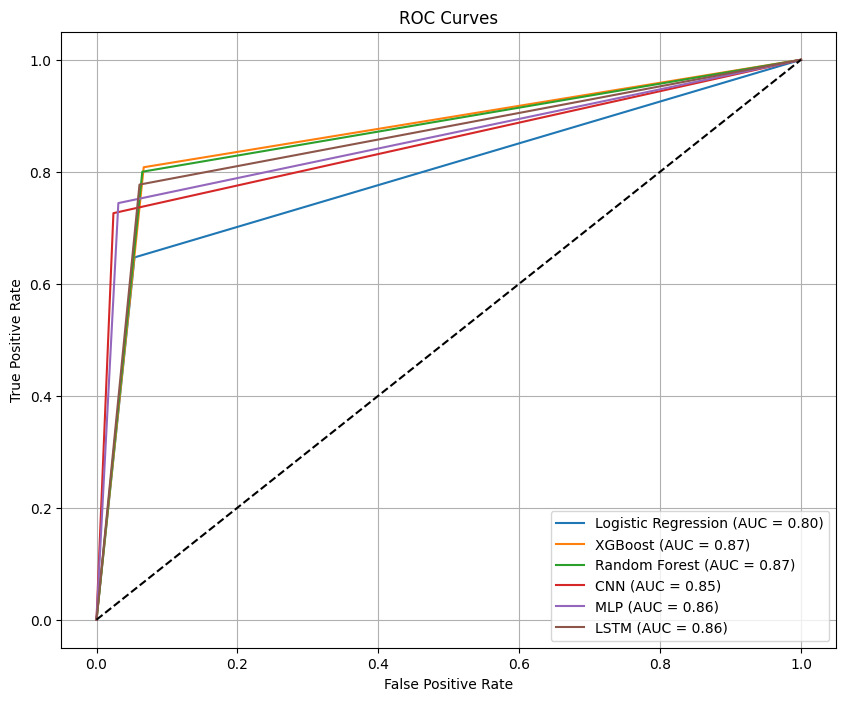

In [ ]:
import concurrent.futures
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Deep learning models
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Machine learning models
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.linear_model import LogisticRegression


# Drop URL column and encode target

X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values

# EDA Visualizations

plt.figure(figsize=(10, 6))
sns.countplot(x='Label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

# Correlation heatmap with Label
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.drop(columns=['Domain']).corr()[['Label']].sort_values('Label', ascending=False),
    annot=True,
    cmap='coolwarm'
)
plt.title('Feature Correlation with Label')
plt.show()

# Normalize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Reshape for deep learning models
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_3d = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# Training parameters
epochs = 50  # Reduced for faster training
batch_size = 64

# ------------------------
# 2. Model Definitions
# ------------------------

def train_mlp():
    model = Sequential([
        Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    callbacks = [
        EarlyStopping(patience=5, restore_best_weights=True),
        ModelCheckpoint('mlp_best.keras', save_best_only=True)
    ]

    model.fit(X_train, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    return model

def train_cnn():
    model = Sequential([
        Conv1D(64, kernel_size=3, activation='relu', input_shape=(X_train_3d.shape[1], 1)),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Conv1D(32, kernel_size=3, activation='relu'),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    callbacks = [
        EarlyStopping(patience=5, restore_best_weights=True),
        ModelCheckpoint('cnn_best.keras', save_best_only=True)
    ]

    model.fit(X_train_3d, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    return model

def train_lstm():
    model = Sequential([
        LSTM(64, input_shape=(X_train_3d.shape[1], 1), return_sequences=False),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    callbacks = [
        EarlyStopping(patience=5, restore_best_weights=True),
        ModelCheckpoint('lstm_best.keras', save_best_only=True)
    ]

    model.fit(X_train_3d, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    return model

def train_rf():
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    return model

def train_xgb():
    model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
    model.fit(X_train, y_train)
    return model

def train_lr():
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    return model

# ------------------------
# 3. Train Models in Parallel
# ------------------------

def evaluate_model(name, model, is_dl=False):
    if is_dl:
        preds = (model.predict(X_test_3d if name in ['CNN', 'LSTM'] else X_test) > 0.5).astype(int)
    else:
        preds = model.predict(X_test)

    print(f"\n=== {name} ===")
    print(classification_report(y_test, preds))

    fpr, tpr, _ = roc_curve(y_test, preds)
    return name, fpr, tpr, auc(fpr, tpr)

models = {
    'MLP': train_mlp,
    'CNN': train_cnn,
    'LSTM': train_lstm,
    'Random Forest': train_rf,
    'XGBoost': train_xgb,
    'Logistic Regression': train_lr
}

trained_models = {}

with concurrent.futures.ThreadPoolExecutor() as executor:
    future_to_name = {executor.submit(func): name for name, func in models.items()}
    for future in concurrent.futures.as_completed(future_to_name):
        name = future_to_name[future]
        try:
            trained_models[name] = future.result()
        except Exception as exc:
            print(f"{name} generated an exception: {exc}")

# ------------------------
# 4. Evaluation and Visualization
# ------------------------

plt.figure(figsize=(10, 8))
for name, model in trained_models.items():
    is_dl = name in ['MLP', 'CNN', 'LSTM']
    name, fpr, tpr, model_auc = evaluate_model(name, model, is_dl)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {model_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


entrainement seq mais pred parallel

Dataset shape: (10000, 18)
Features: ['Domain', 'Have_IP', 'Have_At', 'URL_Length', 'URL_Depth', 'Redirection', 'https_Domain', 'TinyURL', 'Prefix/Suffix', 'DNS_Record', 'Web_Traffic', 'Domain_Age', 'Domain_End', 'iFrame', 'Mouse_Over', 'Right_Click', 'Web_Forwards']

Training mlp...
Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.6278 - auc: 0.6627 - loss: 0.7203 - precision: 0.6471 - recall: 0.5737 - val_accuracy: 0.7925 - val_auc: 0.8603 - val_loss: 0.5350 - val_precision: 0.9069 - val_recall: 0.6687
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7841 - auc: 0.8366 - loss: 0.4706 - precision: 0.8638 - recall: 0.6675 - val_accuracy: 0.8094 - val_auc: 0.8799 - val_loss: 0.4810 - val_precision: 0.9310 - val_recall: 0.6831
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7907 - auc: 0.8476 - loss: 0.4464 - precision: 0.8660 - recall: 0.6802 - val_accuracy: 0.8075 - val_auc: 0.8841 - val_loss: 0.4437 - val_precision: 0.9321 - val_recall: 0.6783
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8165 - auc: 0.8714 - loss: 0.4051 - precision: 0.9031 - recall: 0.7075 - val_accuracy: 0.8163 - val_auc: 0.8825 - val_loss: 0.4206 - val_precision: 0.9621 - val_recall: 0.6723
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.6849 - auc: 0.7359 - loss: 0.6072 - precision: 0.7250 - recall: 0.6114 - val_accuracy: 0.7900 - val_auc: 0.8587 - val_loss: 0.5751 - val_precision: 0.9768 - val_recall: 0.6096
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8002 - auc: 0.8547 - loss: 0.4243 - precision: 0.8852 - recall: 0.6812 - val_accuracy: 0.7744 - val_auc: 0.8602 - val_loss: 0.5461 - val_precision: 0.9875 - val_recall: 0.5723
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7986 - auc: 0.8463 - loss: 0.4350 - precision: 0.8715 - recall: 0.6917 - val_accuracy: 0.7656 - val_auc: 0.8717 - val_loss: 0.5233 - val_precision: 0.9935 - val_recall: 0.5518
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8096 - auc: 0.8534 - loss: 0.4164 - precision: 0.9087 - recall: 0.6904 - val_accuracy: 0.7894 - val_auc: 0.8629 - val_loss: 0.4836 - val_precision: 0.9824 - val_recall: 0.6048
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/s

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.5971 - auc: 0.6002 - loss: 0.6678 - precision: 0.6323 - recall: 0.4238 - val_accuracy: 0.7506 - val_auc: 0.7770 - val_loss: 0.4930 - val_precision: 0.9284 - val_recall: 0.5627
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.7702 - auc: 0.7843 - loss: 0.4765 - precision: 0.9392 - recall: 0.5653 - val_accuracy: 0.7481 - val_auc: 0.8278 - val_loss: 0.4725 - val_precision: 0.9067 - val_recall: 0.5735
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7636 - auc: 0.8095 - loss: 0.4657 - precision: 0.9091 - recall: 0.5890 - val_accuracy: 0.7487 - val_auc: 0.8348 - val_loss: 0.4852 - val_precision: 0.9735 - val_recall: 0.5301
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7503 - auc: 0.8031 - loss: 0.4784 - precision: 0.9010 - recall: 0.5597 - val_accuracy: 0.7575 - val_auc: 0.8409 - val_loss: 0.4654 - val_precision: 0.9585 - val_recall: 0.5566
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/s

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:42:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

=== Stacking Ensemble Evaluation ===
              precision    recall  f1-score   support

           0       0.83      0.92      0.87      1000
           1       0.91      0.81      0.86      1000

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



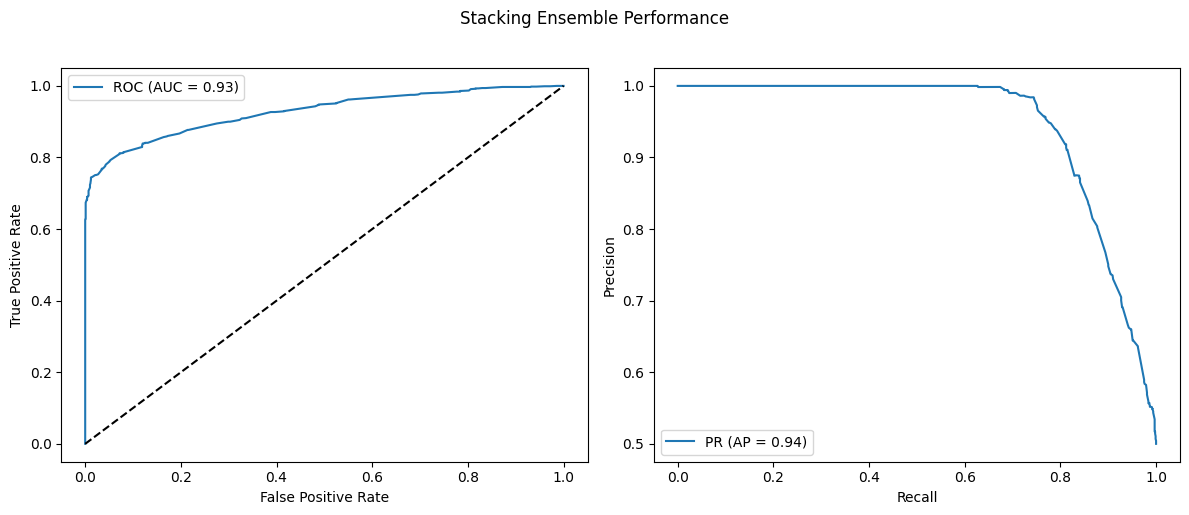


Model Weights in Stacking Ensemble:
Model 1: 2.5278
Model 2: -0.0791
Model 3: -0.2059
Model 4: -0.5273
Model 5: 5.6876


In [ ]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# ---------------------------------------------------
# 1. Data Preparation (Optimized for your 41 features)
# ---------------------------------------------------
# Load your dataset

# Verify we have 41 features + Type column
print(f"Dataset shape: {df.shape}")
print(f"Features: {df.drop(columns=['Label']).columns.tolist()}")

# Handle class imbalance
class_counts = df['Label'].value_counts()
class_weights = {0: 1, 1: class_counts[0]/class_counts[1]}  # Auto weight calculation

# Prepare features and target

X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values

# Normalize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split data with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Reshape for deep learning models (samples, timesteps, channels)
X_train_3d = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_3d = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# ---------------------------------------------------
# 2. Model Definitions (Optimized for 41 features)
# ---------------------------------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy',
                        tf.keras.metrics.Precision(name='precision'),
                        tf.keras.metrics.Recall(name='recall'),
                        tf.keras.metrics.AUC(name='auc')])
    return model

def build_cnn(input_shape):
    model = Sequential([
        Conv1D(64, 3, activation='relu', input_shape=input_shape),
        MaxPooling1D(2),
        BatchNormalization(),
        Dropout(0.4),
        Conv1D(128, 3, activation='relu'),
        MaxPooling1D(2),
        BatchNormalization(),
        Dropout(0.4),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy',
                        tf.keras.metrics.Precision(name='precision'),
                        tf.keras.metrics.Recall(name='recall'),
                        tf.keras.metrics.AUC(name='auc')])
    return model

def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, return_sequences=True, input_shape=input_shape),
        Dropout(0.3),
        LSTM(32),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy',
                        tf.keras.metrics.Precision(name='precision'),
                        tf.keras.metrics.Recall(name='recall'),
                        tf.keras.metrics.AUC(name='auc')])
    return model

# ---------------------------------------------------
# 3. Model Training (Optimized)
# ---------------------------------------------------
def train_model(model, X, y, model_name, epochs=50, batch_size=128):
    print(f"\nTraining {model_name}...")
    callbacks = [
        EarlyStopping(patience=10, monitor='val_auc', mode='max', restore_best_weights=True),
        ModelCheckpoint(f'best_{model_name}.keras', monitor='val_auc', save_best_only=True)
    ]

    history = model.fit(
        X, y,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1
    )
    return model

# Initialize and train models
mlp = train_model(build_mlp(X_train.shape[1]), X_train, y_train, 'mlp')
cnn = train_model(build_cnn((X_train_3d.shape[1], X_train_3d.shape[2])), X_train_3d, y_train, 'cnn')
lstm = train_model(build_lstm((X_train_3d.shape[1], X_train_3d.shape[2])), X_train_3d, y_train, 'lstm')

# Tree-based models
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    scale_pos_weight=class_weights[1],
    random_state=42
).fit(X_train, y_train)

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=None,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
).fit(X_train, y_train)

# ---------------------------------------------------
# 4. Stacking Ensemble (Optimized for your dataset)
# ---------------------------------------------------
def get_meta_features(X, X_3d=None):
    return np.column_stack([
        mlp.predict(X),
        cnn.predict(X_3d),
        lstm.predict(X_3d),
        xgb_model.predict_proba(X)[:, 1],
        rf_model.predict_proba(X)[:, 1]
    ])

meta_train = get_meta_features(X_train, X_train_3d)
meta_test = get_meta_features(X_test, X_test_3d)

meta_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
).fit(meta_train, y_train)

# ---------------------------------------------------
# 5. Comprehensive Evaluation
# ---------------------------------------------------
def full_evaluation(y_true, y_pred, y_proba, model_name):
    print(f"\n=== {model_name} Evaluation ===")
    print(classification_report(y_true, y_pred))

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)

    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_true, y_proba)
    avg_precision = average_precision_score(y_true, y_proba)

    plt.figure(figsize=(12, 5))
    plt.suptitle(f'{model_name} Performance', y=1.02)

    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, label=f'ROC (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(recall, precision, label=f'PR (AP = {avg_precision:.2f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Evaluate stacking model
y_pred_stack = meta_model.predict(meta_test)
y_proba_stack = meta_model.predict_proba(meta_test)[:, 1]
full_evaluation(y_test, y_pred_stack, y_proba_stack, "Stacking Ensemble")

# Show model weights in stacking
print("\nModel Weights in Stacking Ensemble:")
for i, weight in enumerate(meta_model.coef_[0]):
    print(f"Model {i+1}: {weight:.4f}")

## apres osolation forest


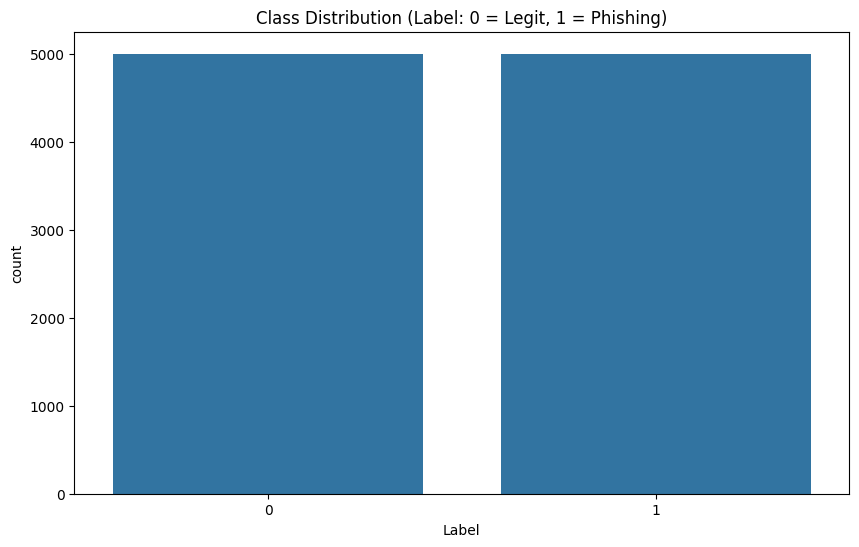

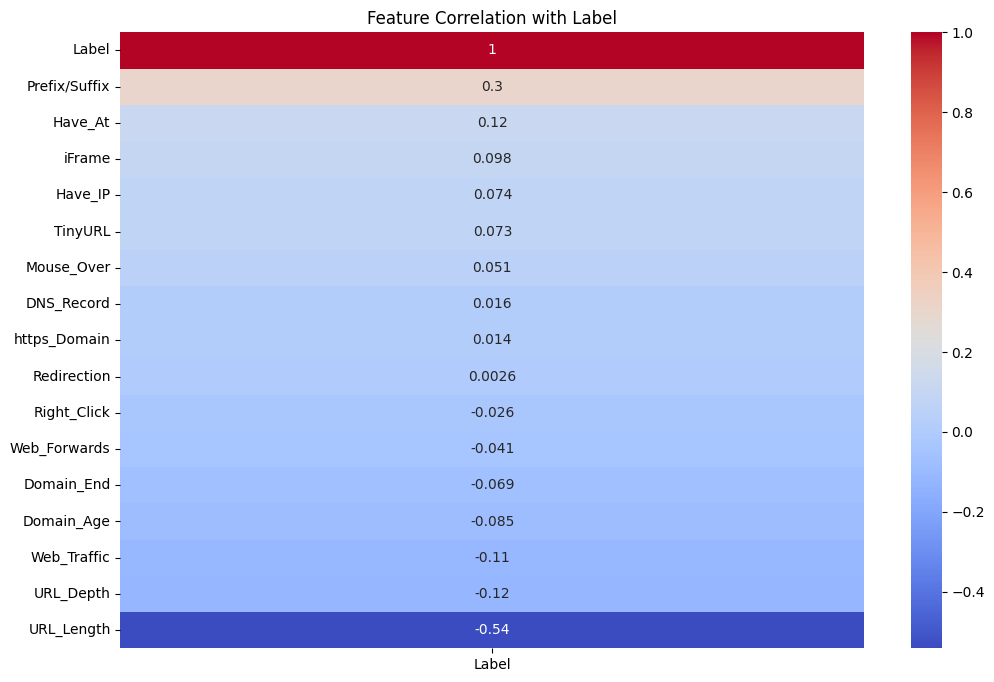

Nombre de points supprimés : 100
Distribution après équilibrage : [4995 4995]
Entraînement du modèle MLP...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


MLP terminé.
Entraînement du modèle CNN...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN terminé.
Entraînement du modèle LSTM...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM terminé.
Entraînement du modèle XGBoost...
XGBoost terminé.
Entraînement du modèle RandomForest...


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:51:15] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


RandomForest terminé.
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Méta-modèle entraîné.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

--- Rapport de classification (Stacking) ---
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       999
           1       0.90      0.81      0.85       999

    accuracy                           0.86      1998
   macro avg       0.86      0.86      0.86      1998
weighted avg       0.86      0.86      0.86      1998



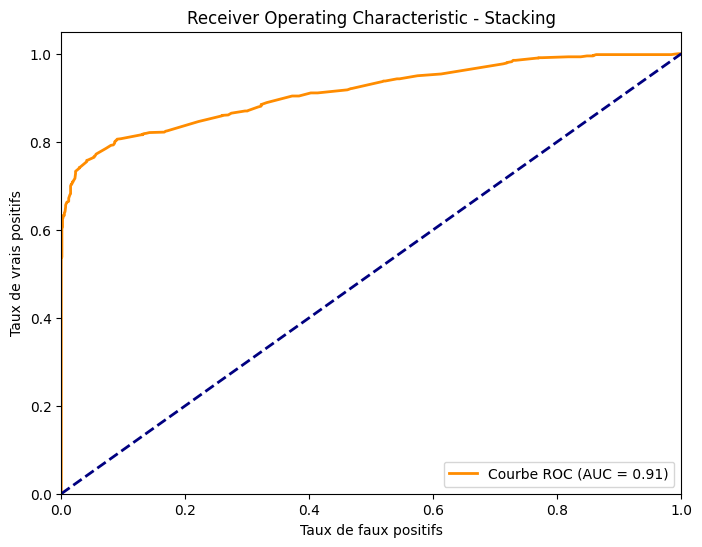

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import RandomForestClassifier, IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (stacking)
from sklearn.linear_model import LogisticRegression


# Préparation des données

X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values


# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='Label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

# Correlation heatmap with Label
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.drop(columns=['Domain']).corr()[['Label']].sort_values('Label', ascending=False),
    annot=True,
    cmap='coolwarm'
)
plt.title('Feature Correlation with Label')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
nombre_supprimes = len(X) - np.sum(mask)
print(f"Nombre de points supprimés : {nombre_supprimes}")

X = X[mask]
y = y[mask]

# Équilibrage de la dataset avec sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Pour les modèles CNN et LSTM, on ajoute une dimension pour le canal
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_3d = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# -------------------------------------------------------
# Définition des modèles de base
# -------------------------------------------------------

# 1. Modèle MLP
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 2. Modèle CNN
def build_cnn(input_shape):
    model = Sequential([
        Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Conv1D(filters=32, kernel_size=3, activation='relu'),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Flatten(),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 3. Modèle LSTM
def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, activation='tanh', return_sequences=True, input_shape=input_shape),
        Dropout(0.3),
        LSTM(32, activation='tanh'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 4. Modèle XGBoost
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

# 5. Modèle RandomForest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# -------------------------------------------------------
# Entraînement des modèles deep learning (MLP, CNN, LSTM)
# -------------------------------------------------------

# Paramètres d'entraînement communs
epochs = 100
batch_size = 64
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement du MLP
mlp = build_mlp(X_train.shape[1])
print("Entraînement du modèle MLP...")
mlp.fit(X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=callbacks,
        class_weight={0: 1, 1: 1.2},
        verbose=0)
print("MLP terminé.")

# Entraînement du CNN
cnn = build_cnn((X_train_3d.shape[1], X_train_3d.shape[2]))
print("Entraînement du modèle CNN...")
cnn.fit(X_train_3d, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=callbacks,
        class_weight={0: 1, 1: 1.2},
        verbose=0)
print("CNN terminé.")

# Entraînement du LSTM
lstm = build_lstm((X_train_3d.shape[1], X_train_3d.shape[2]))
print("Entraînement du modèle LSTM...")
lstm.fit(X_train_3d, y_train,
         epochs=epochs,
         batch_size=batch_size,
         validation_split=0.2,
         callbacks=callbacks,
         class_weight={0: 1, 1: 1.2},
         verbose=0)
print("LSTM terminé.")

# -------------------------------------------------------
# Entraînement des modèles scikit-learn (XGBoost, RandomForest)
# -------------------------------------------------------
print("Entraînement du modèle XGBoost...")
xgb_model.fit(X_train, y_train)
print("XGBoost terminé.")

print("Entraînement du modèle RandomForest...")
rf_model.fit(X_train, y_train)
print("RandomForest terminé.")

# -------------------------------------------------------
# Création des features pour le méta-modèle
# -------------------------------------------------------
# On récupère les probabilités prédites par chacun des modèles sur l'ensemble d'entraînement
meta_train_mlp   = mlp.predict(X_train)
meta_train_cnn   = cnn.predict(X_train_3d)
meta_train_lstm  = lstm.predict(X_train_3d)
meta_train_xgb   = xgb_model.predict_proba(X_train)[:, 1].reshape(-1, 1)
meta_train_rf    = rf_model.predict_proba(X_train)[:, 1].reshape(-1, 1)

# Concaténation des prédictions pour former le jeu de features du méta-modèle
meta_features_train = np.concatenate([meta_train_mlp, meta_train_cnn, meta_train_lstm,
                                        meta_train_xgb, meta_train_rf], axis=1)

# Création du méta-modèle (ici, une régression logistique)
meta_model = LogisticRegression()
meta_model.fit(meta_features_train, y_train)
print("Méta-modèle entraîné.")

# -------------------------------------------------------
# Prédictions sur l'ensemble de test
# -------------------------------------------------------
meta_test_mlp   = mlp.predict(X_test)
meta_test_cnn   = cnn.predict(X_test_3d)
meta_test_lstm  = lstm.predict(X_test_3d)
meta_test_xgb   = xgb_model.predict_proba(X_test)[:, 1].reshape(-1, 1)
meta_test_rf    = rf_model.predict_proba(X_test)[:, 1].reshape(-1, 1)

meta_features_test = np.concatenate([meta_test_mlp, meta_test_cnn, meta_test_lstm,
                                       meta_test_xgb, meta_test_rf], axis=1)

# Prédiction finale via le méta-modèle
y_pred_stack = meta_model.predict(meta_features_test)

# -------------------------------------------------------
# Évaluation des performances
# -------------------------------------------------------
print("\n--- Rapport de classification (Stacking) ---")
print(classification_report(y_test, y_pred_stack))

# Calcul de la courbe ROC pour le méta-modèle
proba_stack = meta_model.predict_proba(meta_features_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_stack)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Stacking')
plt.legend(loc="lower right")
plt.show()


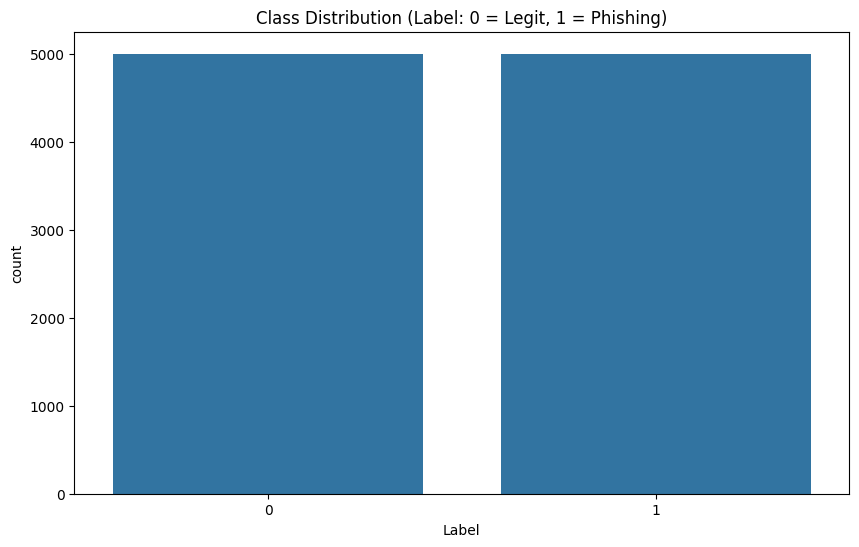

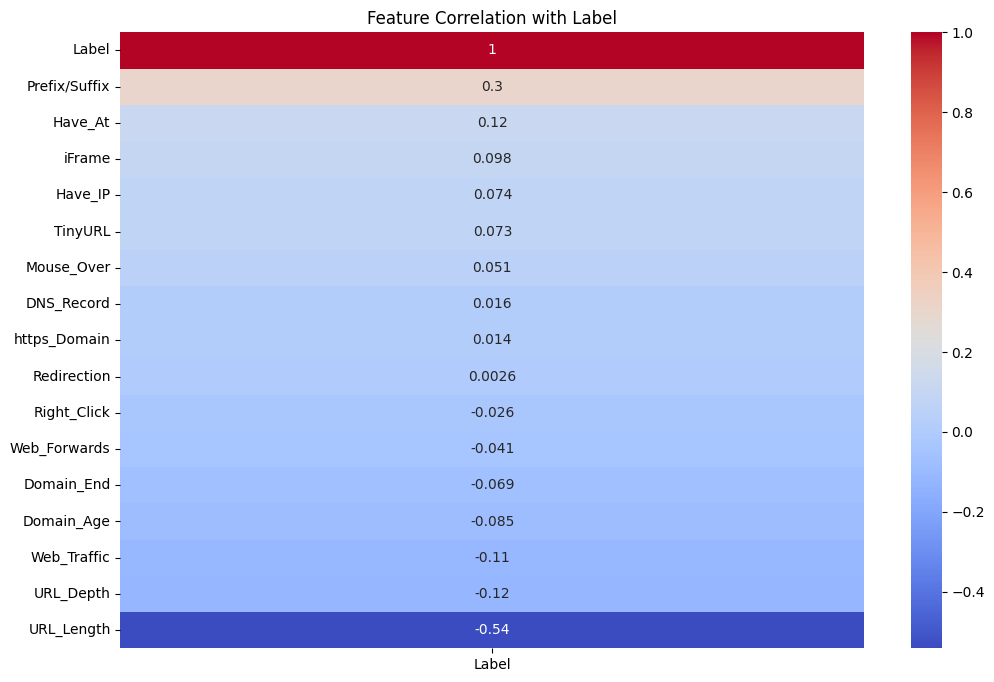

Nombre de points supprimés : 100
Distribution après équilibrage : [4995 4995]

Entraînement du modèle MLP 1/5...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/5...


Modèle 2 terminé.

Entraînement du modèle MLP 3/5...


Modèle 3 terminé.

Entraînement du modèle MLP 4/5...
Modèle 4 terminé.

Entraînement du modèle MLP 5/5...
Modèle 5 terminé.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Rapport de classification (Bagging - MLP) ---
              precision    recall  f1-score   support

           0       0.80      0.94      0.87       999
           1       0.93      0.76      0.84       999

    accuracy                           0.85      1998
   macro avg       0.87      0.85      0.85      1998
weighted avg       0.87      0.85      0.85      1998



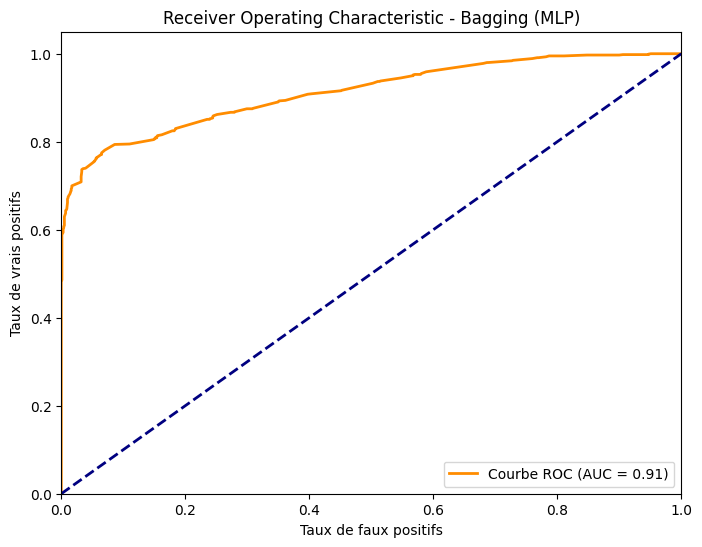

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (pour l'exemple précédent, ici nous utilisons le bagging pour un MLP)
from sklearn.linear_model import LogisticRegression


# Préparation des données
X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='Label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

# Correlation heatmap with Label
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.drop(columns=['Domain']).corr()[['Label']].sort_values('Label', ascending=False),
    annot=True,
    cmap='coolwarm'
)
plt.title('Feature Correlation with Label')
plt.show()

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
nombre_supprimes = len(X) - np.sum(mask)
print(f"Nombre de points supprimés : {nombre_supprimes}")

X = X[mask]
y = y[mask]

# Équilibrage de la dataset avec sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# -------------------------------------------------------
# Définition du modèle de base (MLP)
# -------------------------------------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# -------------------------------------------------------
# Mise en place du Bagging pour le modèle MLP
# -------------------------------------------------------
import random

n_estimators = 5         # Nombre de modèles dans l'ensemble
epochs = 100
batch_size = 64

bagging_models = []      # Liste pour stocker les modèles
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement de chaque modèle sur un bootstrap (échantillonnage avec remplacement)
for i in range(n_estimators):
    print(f"\nEntraînement du modèle MLP {i+1}/{n_estimators}...")
    # Création d'un échantillon bootstrap
    indices = np.random.choice(np.arange(len(X_train)), size=len(X_train), replace=True)
    X_train_boot = X_train[indices]
    y_train_boot = y_train[indices]

    # Construction et entraînement du modèle
    model = build_mlp(X_train.shape[1])
    model.fit(X_train_boot, y_train_boot,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    bagging_models.append(model)
    print(f"Modèle {i+1} terminé.")

# -------------------------------------------------------
# Agrégation des prédictions (vote majoritaire via moyenne des probabilités)
# -------------------------------------------------------
# Prédiction pour chaque modèle sur l'ensemble de test
predictions = []
for model in bagging_models:
    pred = model.predict(X_test)
    predictions.append(pred)

# Convertir la liste en tableau et calculer la moyenne
predictions = np.array(predictions)  # forme: (n_estimators, n_samples, 1)
avg_predictions = np.mean(predictions, axis=0)

# Appliquer un seuil de 0.5 pour obtenir la classe finale
y_pred_bagging = (avg_predictions >= 0.5).astype(int).ravel()

# Évaluation des performances
print("\n--- Rapport de classification (Bagging - MLP) ---")
print(classification_report(y_test, y_pred_bagging))

# Calcul de la courbe ROC pour le bagging
proba_bagging = avg_predictions.ravel()
fpr, tpr, thresholds = roc_curve(y_test, proba_bagging)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Bagging (MLP)')
plt.legend(loc="lower right")
plt.show()


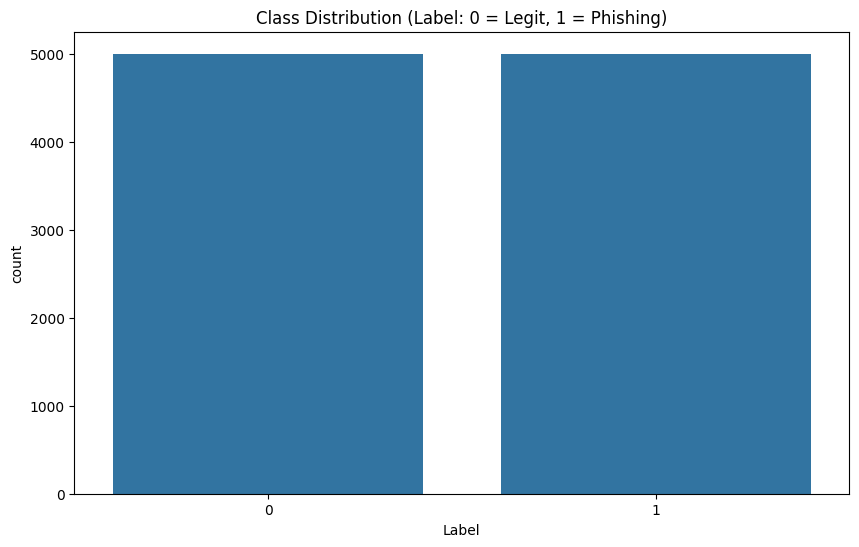

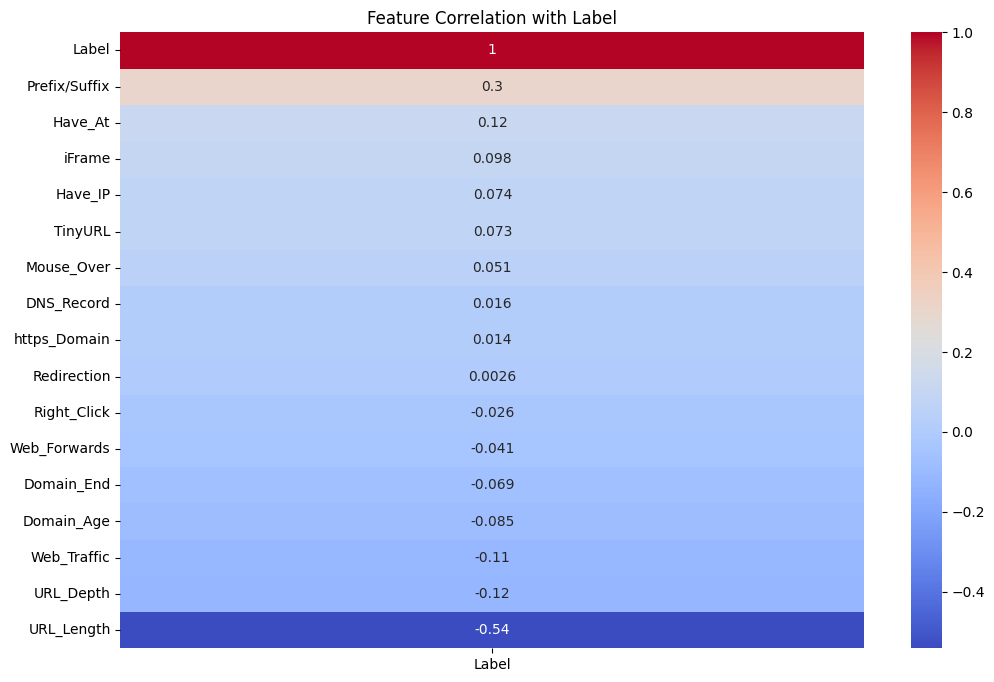

Pour une contamination de 0.005, points supprimés : 49
Pour une contamination de 0.01, points supprimés : 100
Pour une contamination de 0.02, points supprimés : 200
Distribution après SMOTE : [4995 4995]

=== Entraînement avec 3 estimateurs ===

Entraînement du modèle MLP 1/3...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/3...


Modèle 2 terminé.

Entraînement du modèle MLP 3/3...
Modèle 3 terminé.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.80      0.94      0.87       999
           1       0.93      0.77      0.84       999

    accuracy                           0.85      1998
   macro avg       0.86      0.85      0.85      1998
weighted avg       0.86      0.85      0.85      1998



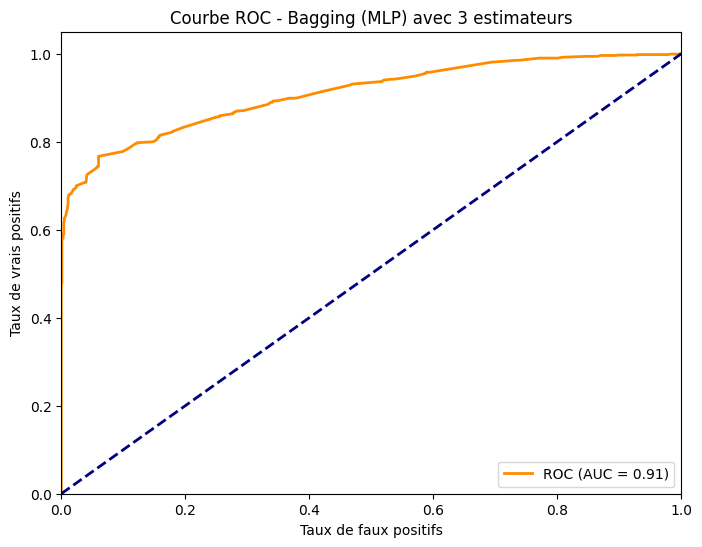


=== Entraînement avec 5 estimateurs ===

Entraînement du modèle MLP 1/5...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/5...
Modèle 2 terminé.

Entraînement du modèle MLP 3/5...
Modèle 3 terminé.

Entraînement du modèle MLP 4/5...
Modèle 4 terminé.

Entraînement du modèle MLP 5/5...
Modèle 5 terminé.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.81      0.93      0.86       999
           1       0.92      0.78      0.84       999

    accuracy                           0.85      1998
   macro avg       0.86      0.85      0.85      1998
weighted avg       0.86      0.85      0.85      1998



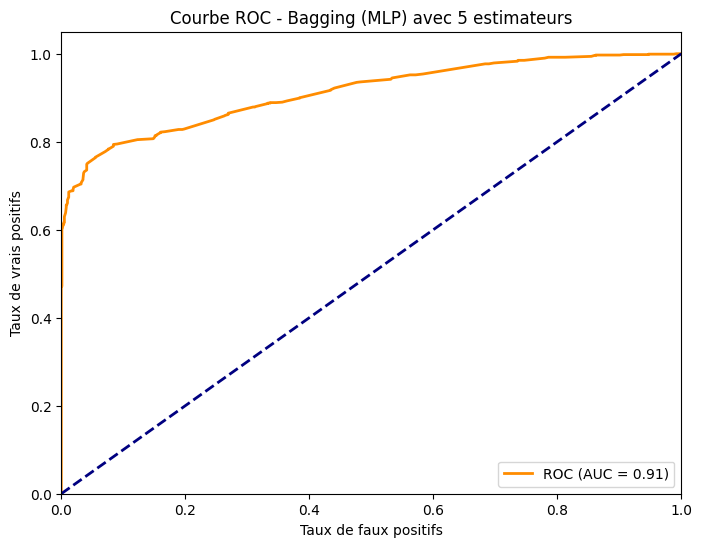


=== Entraînement avec 7 estimateurs ===

Entraînement du modèle MLP 1/7...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/7...
Modèle 2 terminé.

Entraînement du modèle MLP 3/7...
Modèle 3 terminé.

Entraînement du modèle MLP 4/7...
Modèle 4 terminé.

Entraînement du modèle MLP 5/7...
Modèle 5 terminé.

Entraînement du modèle MLP 6/7...
Modèle 6 terminé.

Entraînement du modèle MLP 7/7...
Modèle 7 terminé.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.80      0.94      0.87       999
           1       0.93      0.77      0.84       999

    accuracy                           0.85      1998
   macro avg       0.86      0.85      0.85      1998
weighted avg       0.86      0.85      0.85      1998



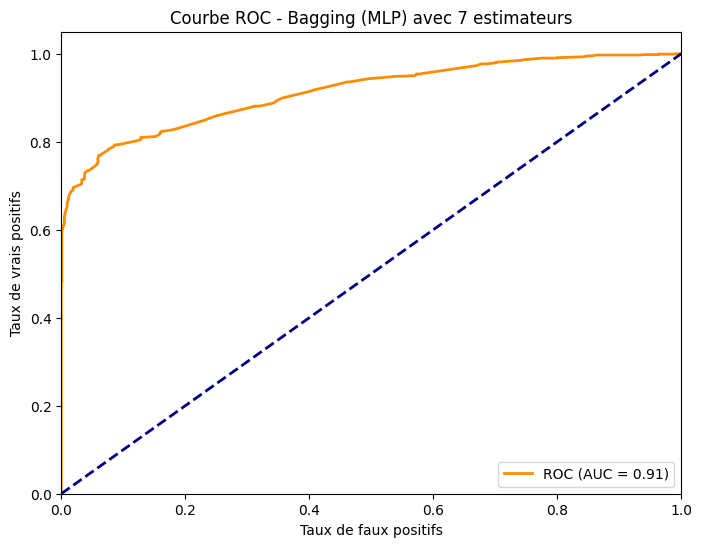


=== Entraînement avec 10 estimateurs ===

Entraînement du modèle MLP 1/10...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/10...
Modèle 2 terminé.

Entraînement du modèle MLP 3/10...
Modèle 3 terminé.

Entraînement du modèle MLP 4/10...
Modèle 4 terminé.

Entraînement du modèle MLP 5/10...
Modèle 5 terminé.

Entraînement du modèle MLP 6/10...
Modèle 6 terminé.

Entraînement du modèle MLP 7/10...
Modèle 7 terminé.

Entraînement du modèle MLP 8/10...
Modèle 8 terminé.

Entraînement du modèle MLP 9/10...
Modèle 9 terminé.

Entraînement du modèle MLP 10/10...


Modèle 10 terminé.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.79      0.95      0.86       999
           1       0.93      0.74      0.83       999

    accuracy                           0.85      1998
   macro avg       0.86      0.85      0.84      1998
weighted avg       0.86      0.85      0.84      1998



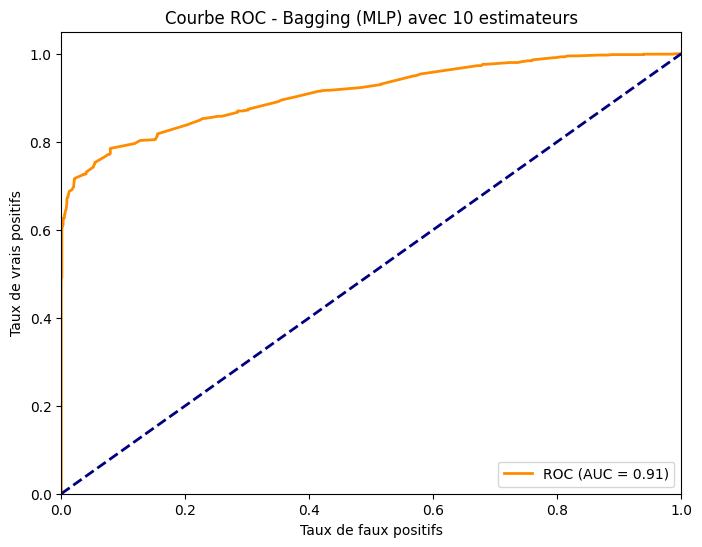

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Détection d'anomalies
from sklearn.ensemble import IsolationForest

# Pour équilibrer la dataset avec SMOTE
from imblearn.over_sampling import SMOTE

# Pour le Bagging
import random

# Préparation des données
X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='Label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

# Correlation heatmap with Label
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.drop(columns=['Domain']).corr()[['Label']].sort_values('Label', ascending=False),
    annot=True,
    cmap='coolwarm'
)
plt.title('Feature Correlation with Label')
plt.show()

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------
# 1. Suppression des anomalies
# ---------------------------
# Essai de différents niveaux de contamination pour IsolationForest
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X) - np.sum(mask)
    print(f"Pour une contamination de {contamination}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination (par exemple 1%)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
X = X[mask]
y = y[mask]

# ---------------------------
# 2. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)
print("Distribution après SMOTE :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# ---------------------------
# 3. Définition du modèle MLP
# ---------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# ---------------------------
# 4. Fonction d'entraînement du Bagging
# ---------------------------
epochs = 100
batch_size = 64

callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

def train_bagging_model(n_estimators, X_train, y_train):
    bagging_models = []
    for i in range(n_estimators):
        print(f"\nEntraînement du modèle MLP {i+1}/{n_estimators}...")
        # Création d'un échantillon bootstrap
        indices = np.random.choice(np.arange(len(X_train)), size=len(X_train), replace=True)
        X_train_boot = X_train[indices]
        y_train_boot = y_train[indices]

        model = build_mlp(X_train.shape[1])
        model.fit(X_train_boot, y_train_boot,
                  epochs=epochs,
                  batch_size=batch_size,
                  validation_split=0.2,
                  callbacks=callbacks,
                  class_weight={0: 1, 1: 1.2},
                  verbose=0)
        bagging_models.append(model)
        print(f"Modèle {i+1} terminé.")
    return bagging_models

# ---------------------------
# 5. Expérimentation avec différents nombres d'estimateurs
# ---------------------------
# Vous pouvez expérimenter avec plusieurs valeurs
for n in [3, 5, 7, 10]:
    print(f"\n=== Entraînement avec {n} estimateurs ===")
    bagging_models = train_bagging_model(n, X_train, y_train)

    # Agrégation des prédictions sur l'ensemble de test
    predictions = []
    for model in bagging_models:
        pred = model.predict(X_test)
        predictions.append(pred)

    # Calcul de la moyenne des prédictions
    predictions = np.array(predictions)  # forme: (n_estimators, n_samples, 1)
    avg_predictions = np.mean(predictions, axis=0)

    # Application du seuil 0.5 pour obtenir la classe finale
    y_pred = (avg_predictions >= 0.5).astype(int).ravel()

    # Évaluation des performances
    print("\n--- Rapport de classification ---")
    print(classification_report(y_test, y_pred))

    # Calcul et affichage de la courbe ROC
    proba = avg_predictions.ravel()
    fpr, tpr, thresholds = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taux de faux positifs')
    plt.ylabel('Taux de vrais positifs')
    plt.title(f'Courbe ROC - Bagging (MLP) avec {n} estimateurs')
    plt.legend(loc="lower right")
    plt.show()


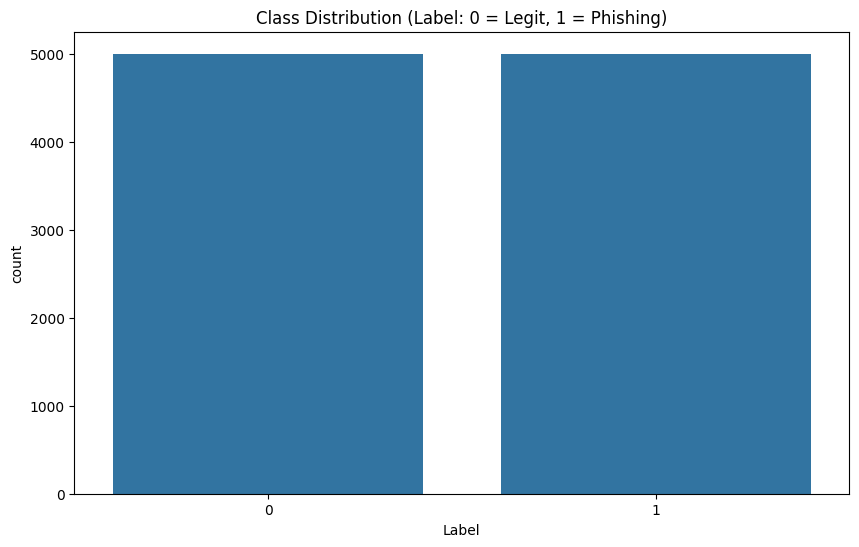

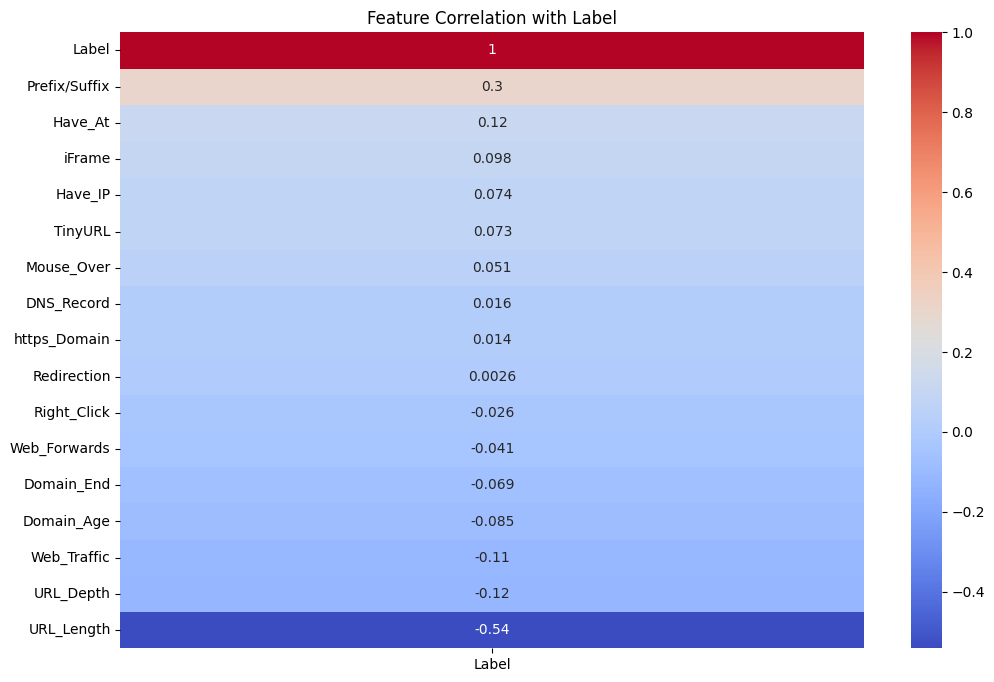

Nombre de points supprimés : 100
Distribution après équilibrage : [4995 4995]


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
186/200 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6934 - loss: 0.6676

200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6968 - loss: 0.6603 - val_accuracy: 0.7999 - val_loss: 0.4398
Epoch 2/50
196/200 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7827 - loss: 0.4685

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7827 - loss: 0.4684 - val_accuracy: 0.8161 - val_loss: 0.3972
Epoch 3/50
198/200 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7945 - loss: 0.4398

...

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8262 - loss: 0.3864 - val_accuracy: 0.8274 - val_loss: 0.3686
Epoch 17/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8246 - loss: 0.3868 - val_accuracy: 0.8293 - val_loss: 0.3706
Epoch 18/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8214 - loss: 0.3934 - val_accuracy: 0.8243 - val_loss: 0.3723
Epoch 19/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8241 - loss: 0.3911 - val_accuracy: 0.8268 - val_loss: 0.3713
Epoch 20/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8245 - loss: 0.3830 - val_accuracy: 0.8305 - val_loss: 0.3699
Epoch 21/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8285 - loss: 0.3794

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8285 - loss: 0.3794 - val_accuracy: 0.8293 - val_loss: 0.3668
Epoch 22/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8366 - loss: 0.3730 - val_accuracy: 0.8268 - val_loss: 0.3710
Epoch 23/50
190/200 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8257 - loss: 0.3814

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8261 - loss: 0.3808 - val_accuracy: 0.8249 - val_loss: 0.3651
Epoch 24/50
197/200 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8385 - loss: 0.3598

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8385 - loss: 0.3600 - val_accuracy: 0.8236 - val_loss: 0.3648
Epoch 25/50
186/200 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8410 - loss: 0.3696

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8404 - loss: 0.3698 - val_accuracy: 0.8280 - val_loss: 0.3623
Epoch 26/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8340 - loss: 0.3713 - val_accuracy: 0.8261 - val_loss: 0.3650
Epoch 27/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8493 - loss: 0.3502 - val_accuracy: 0.8324 - val_loss: 0.3634
Epoch 28/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8263 - loss: 0.3811 - val_accuracy: 0.8286 - val_loss: 0.3654
Epoch 29/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8318 - loss: 0.3670 - val_accuracy: 0.8286 - val_loss: 0.3637
Epoch 30/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8280 - loss: 0.3764 - val_accuracy: 0.8305 - val_loss: 0.3637
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
              precision    recall  f1-score   support

           0       0.77      0.93      0.84       999
           1       0.91      0.72      0.81       999

    accuracy                       

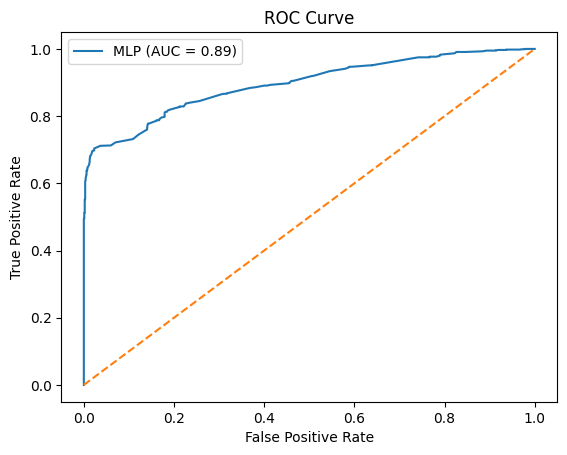

In [3]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import RandomForestClassifier, IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (stacking)
from sklearn.linear_model import LogisticRegression

# Préparation des données
X = df.drop(columns=['Domain', 'Label']).values
y = df['Label'].astype(int).values

# ----------------------------------------
# Visualisation exploratoire
# ----------------------------------------

plt.figure(figsize=(10, 6))
sns.countplot(x='Label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(
    df.drop(columns=['Domain']).corr()[['Label']].sort_values('Label', ascending=False),
    annot=True,
    cmap='coolwarm'
)
plt.title('Feature Correlation with Label')
plt.show()

# ----------------------------------------
# Prétraitement
# ----------------------------------------

# Normalisation
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1
X = X[mask]
y = y[mask]
print(f"Nombre de points supprimés : {len(pred_anomalies) - np.sum(mask)}")

# Sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Pour CNN / LSTM
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_3d = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# ----------------------------------------
# Modèles
# ----------------------------------------

# MLP Model
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# CNN Model
def build_cnn(input_shape):
    model = Sequential([
        Conv1D(64, 3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),
        Dropout(0.3),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# LSTM Model
def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, input_shape=input_shape),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# ----------------------------------------
# Entraînement (MLP exemple)
# ----------------------------------------

early_stop = EarlyStopping(patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_mlp_model.h5', save_best_only=True)

model = build_mlp(X_train.shape[1])
history = model.fit(X_train, y_train,
                    validation_split=0.2,
                    epochs=50,
                    batch_size=32,
                    callbacks=[early_stop, checkpoint])

# ----------------------------------------
# Évaluation
# ----------------------------------------

y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label='MLP (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()
